In [1]:
# data = 'https://raw.githubusercontent.com/DataTalksClub/machine-learning-zoomcamp/main/cohorts/2026/data/car_fuel_efficiency_2026.csv'
# !wget $data

In [2]:
import pandas as pd
import numpy as np
import seaborn as sns
from matplotlib import pyplot as plt

In [3]:
df = pd.read_csv("car_fuel_efficiency_2026.csv")
df.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration,fuel_efficiency_mpg
0,2006,Europe,Gasoline,Front-wheel drive,4,2180,6,243.0,3870,NaN,31.9
1,2008,Europe,Diesel,Front-wheel drive,4,2390,6,272.0,4210,NaN,31.3
2,1996,Asia,Gasoline,Front-wheel drive,5,2320,6,267.0,4240,17.3,27.5
3,1989,Europe,Gasoline,Front-wheel drive,4,2130,6,258.0,4490,18.7,28.5
4,1994,USA,Diesel,Front-wheel drive,3,2580,7,304.0,4510,17.5,31.0


In [4]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.feature_extraction import DictVectorizer
from sklearn.metrics import roc_auc_score
from sklearn.tree import export_text

In [5]:
df_full_train, df_test = train_test_split(df, test_size=0.2, random_state=1)
df_train, df_val = train_test_split(
    df_full_train, test_size=0.25, random_state=1
)
df_train = df_train.reset_index(drop=True)
df_val = df_val.reset_index(drop=True)
df_test = df_test.reset_index(drop=True)

y_train = (df_train['fuel_efficiency_mpg']).astype('float').values
y_val = (df_val['fuel_efficiency_mpg']).astype('float').values
y_test = (df_test['fuel_efficiency_mpg']).astype('float').values

In [6]:
del df_train['fuel_efficiency_mpg']
del df_val['fuel_efficiency_mpg']
del df_test['fuel_efficiency_mpg']

In [7]:
df_train.head()

,model_year,origin,fuel_type,drivetrain,num_doors,engine_displacement,num_cylinders,horsepower,vehicle_weight,acceleration
0,2011,USA,Gasoline,Front-wheel drive,4,2370,6,284.0,4280,19.0
1,2012,USA,Diesel,All-wheel drive,3,2460,6,288.0,4580,18.8
2,1985,Europe,Gasoline,All-wheel drive,3,2070,6,230.0,4150,20.6
3,2005,Europe,Diesel,Front-wheel drive,5,2050,5,249.0,4120,NaN
4,2004,Asia,Gasoline,Front-wheel drive,2,2160,6,241.0,4020,17.9


In [8]:
train_dicts = df_train.fillna(0).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_train = dv.fit_transform(train_dicts)

dv.get_feature_names_out()

array(['acceleration', 'drivetrain=All-wheel drive',
       'drivetrain=Front-wheel drive', 'drivetrain=Rear-wheel drive',
       'engine_displacement', 'fuel_type=Diesel', 'fuel_type=Gasoline',
       'fuel_type=Hybrid', 'horsepower', 'model_year', 'num_cylinders',
       'num_doors', 'origin=Asia', 'origin=Europe', 'origin=USA',
       'vehicle_weight'], dtype=object)

In [9]:
val_dicts = df_val.fillna(0).to_dict(orient='records')

dv = DictVectorizer(sparse=False)
X_val = dv.fit_transform(val_dicts)

dv.get_feature_names_out()

array(['acceleration', 'drivetrain=All-wheel drive',
       'drivetrain=Front-wheel drive', 'drivetrain=Rear-wheel drive',
       'engine_displacement', 'fuel_type=Diesel', 'fuel_type=Gasoline',
       'fuel_type=Hybrid', 'horsepower', 'model_year', 'num_cylinders',
       'num_doors', 'origin=Asia', 'origin=Europe', 'origin=USA',
       'vehicle_weight'], dtype=object)

In [10]:
# Q1 -- model_year
dt = DecisionTreeRegressor(max_depth=1)
dt.fit(X_train, y_train)

y_pred = dt.predict(X_train)
# auc = roc_auc_score(y_train, y_pred)
# print('train:', auc)

y_pred = dt.predict(X_val)
# auc = roc_auc_score(y_val, y_pred)
# print('val:', auc)

from sklearn.tree import export_text
print(export_text(dt, feature_names=dv.get_feature_names_out()))

|--- model_year <= 1997.50
|   |--- value: [28.61]
|--- model_year >  1997.50
|   |--- value: [31.17]



In [11]:
# Q2 -- 1.834
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_squared_error

rf = RandomForestRegressor(n_estimators=10, random_state=1, n_jobs=-1)
rf.fit(X_train, y_train)

y_pred = rf.predict(X_val)

rmse = np.sqrt(mean_squared_error(y_val, y_pred))
print('Validation RMSE:', rmse)


Validation RMSE: 1.8336350509302553


In [12]:
# Q3 -- 100 has lowest
score = {}
n_estimators = [10, 50, 100, 150]

for estimator in n_estimators:
    
    rf = RandomForestRegressor(n_estimators=estimator, random_state=1, n_jobs=-1)
    rf.fit(X_train, y_train)
    
    y_pred = rf.predict(X_val)
    
    rmse = np.sqrt(mean_squared_error(y_val, y_pred))
    score[estimator] = round(float(rmse), 5)
score
# print('Validation RMSE: %.3f', rmse)

{10: 1.83364, 50: 1.76963, 100: 1.76752, 150: 1.76753}

In [13]:
# Q4 -- 10 max_depth has minimum error
scores = []
n_estimators = [10, 50, 100, 150]
max_depths = [10, 15, 20, 25]

for max_depth in max_depths:
    for estimator in n_estimators:
        
        rf = RandomForestRegressor(n_estimators=estimator, random_state=1, n_jobs=-1, max_depth=max_depth)
        rf.fit(X_train, y_train)
        
        y_pred = rf.predict(X_val)
        
        rmse = np.sqrt(mean_squared_error(y_val, y_pred))
        scores.append((max_depth, estimator, round(float(rmse), 5)))

columns = ['max_depth', 'estimator', 'rmse']
df_scores = pd.DataFrame(scores, columns=columns)

df_scores.groupby('max_depth').mean()

,estimator,rmse
max_depth,,
10,77.5,1.756868
15,77.5,1.784782
20,77.5,1.782675
25,77.5,1.787375


In [14]:
# Q5 -- vehicle weight

dt = RandomForestRegressor(max_depth=20, n_estimators=10, random_state=1, n_jobs=-1)
dt.fit(X_train, y_train)

y_pred = dt.predict(X_train)
# auc = roc_auc_score(y_train, y_pred)
# print('train:', auc)

y_pred = dt.predict(X_val)
# auc = roc_auc_score(y_val, y_pred)
# print('val:', auc)

importances = dt.feature_importances_
feature_names = dv.get_feature_names_out()

df_importances = pd.DataFrame({
    'feature': feature_names,
    'importance': importances
}).sort_values('importance', ascending=False)

print(df_importances)

                         feature  importance
9                     model_year    0.295822
15                vehicle_weight    0.203649
6             fuel_type=Gasoline    0.160713
8                     horsepower    0.078254
4            engine_displacement    0.061008
0                   acceleration    0.055466
14                    origin=USA    0.042232
5               fuel_type=Diesel    0.021128
2   drivetrain=Front-wheel drive    0.020005
11                     num_doors    0.019724
7               fuel_type=Hybrid    0.011685
1     drivetrain=All-wheel drive    0.007873
10                 num_cylinders    0.006939
12                   origin=Asia    0.006479
3    drivetrain=Rear-wheel drive    0.005636
13                 origin=Europe    0.003389


In [15]:
# Q6 -- 0.3
import sys
!{sys.executable} -m pip install xgboost
import xgboost as xgb


[notice] A new release of pip is available: 26.2.1 -> 26.3
[notice] To update, run: /usr/local/python/3.14.2/bin/python3 -m pip install --upgrade pip


In [16]:
features = list(dv.get_feature_names_out())
dtrain = xgb.DMatrix(X_train, label=y_train, feature_names=features) # DMatrix instead of numpy
dval = xgb.DMatrix(X_val, label=y_val, feature_names=features)

In [22]:
%%capture outputtt
watchlist = [(dtrain, 'train'), (dval, 'val')]

xgb_params = {
    'eta': 0.1, 
    'max_depth': 6,
    'min_child_weight': 1,
    
    'objective': 'reg:squarederror',
    'nthread': 8,
    
    'seed': 1,
    'verbosity': 1,
}

model = xgb.train(xgb_params, dtrain, num_boost_round=100,
                  verbose_eval=5,
                  evals=watchlist)

In [23]:
print(outputtt.stdout) # 0.1

[0]	train-rmse:2.74739	val-rmse:2.78635
[5]	train-rmse:2.12109	val-rmse:2.20428
[10]	train-rmse:1.80592	val-rmse:1.93152
[15]	train-rmse:1.64286	val-rmse:1.80346
[20]	train-rmse:1.55847	val-rmse:1.75076
[25]	train-rmse:1.50918	val-rmse:1.72751
[30]	train-rmse:1.47544	val-rmse:1.71667
[35]	train-rmse:1.44978	val-rmse:1.71287
[40]	train-rmse:1.43074	val-rmse:1.71289
[45]	train-rmse:1.41543	val-rmse:1.71310
[50]	train-rmse:1.40368	val-rmse:1.71358
[55]	train-rmse:1.39009	val-rmse:1.71570
[60]	train-rmse:1.37884	val-rmse:1.71688
[65]	train-rmse:1.37172	val-rmse:1.71812
[70]	train-rmse:1.36283	val-rmse:1.71919
[75]	train-rmse:1.35099	val-rmse:1.72057
[80]	train-rmse:1.34578	val-rmse:1.72100
[85]	train-rmse:1.33480	val-rmse:1.72192
[90]	train-rmse:1.32546	val-rmse:1.72303
[95]	train-rmse:1.32292	val-rmse:1.72324
[99]	train-rmse:1.31192	val-rmse:1.72481



In [21]:
print(outputt.stdout) # 0.3

[0]	train-rmse:2.40653	val-rmse:2.46782
[5]	train-rmse:1.59328	val-rmse:1.76216
[10]	train-rmse:1.47125	val-rmse:1.73205
[15]	train-rmse:1.41908	val-rmse:1.73512
[20]	train-rmse:1.39368	val-rmse:1.73766
[25]	train-rmse:1.35837	val-rmse:1.74359
[30]	train-rmse:1.33243	val-rmse:1.74548
[35]	train-rmse:1.29290	val-rmse:1.75198
[40]	train-rmse:1.25326	val-rmse:1.76296
[45]	train-rmse:1.21527	val-rmse:1.77244
[50]	train-rmse:1.18645	val-rmse:1.77517
[55]	train-rmse:1.14797	val-rmse:1.78668
[60]	train-rmse:1.10265	val-rmse:1.79401
[65]	train-rmse:1.06590	val-rmse:1.80143
[70]	train-rmse:1.04604	val-rmse:1.80444
[75]	train-rmse:1.02727	val-rmse:1.80682
[80]	train-rmse:0.99487	val-rmse:1.81308
[85]	train-rmse:0.96970	val-rmse:1.81600
[90]	train-rmse:0.94986	val-rmse:1.82135
[95]	train-rmse:0.91805	val-rmse:1.82544
[99]	train-rmse:0.90106	val-rmse:1.82646



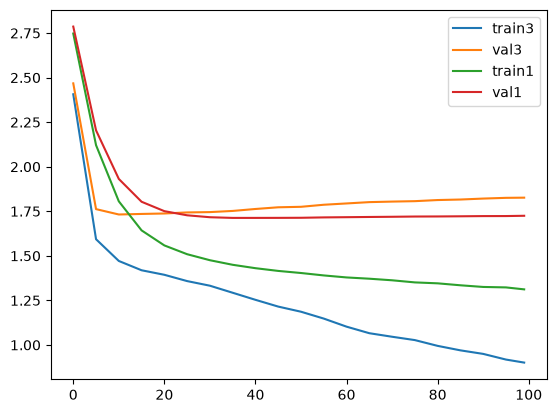

In [25]:
def parse_xgb_output(output):
    results = []

    for line in output.stdout.strip().split('\n'):
        it_line, train_line, val_line = line.split('\t')

        it = int(it_line.strip('[]'))
        train = float(train_line.split(':')[1])
        val = float(val_line.split(':')[1])

        results.append((it, train, val))

    columns = ['num_iter', 'train_rmse', 'val_rmse']
    df_results = pd.DataFrame(results, columns=columns)
    return df_results

df_score_three = parse_xgb_output(outputt)
df_score_one = parse_xgb_output(outputtt)

# over fitting (gap)
plt.plot(df_score_three.num_iter, df_score_three.train_rmse, label='train3')
plt.plot(df_score_three.num_iter, df_score_three.val_rmse, label='val3')
plt.plot(df_score_one.num_iter, df_score_one.train_rmse, label='train1')
plt.plot(df_score_one.num_iter, df_score_one.val_rmse, label='val1')
plt.legend()